# Seasonal Agriculture Performance Analysis

**VOIS AICTE Batch 1, 2026-2027 — Major Project**

This notebook looks at how farming performance shifts across the three growing seasons in the dataset — Kharif, Rabi and Zaid. The idea is simple: farming doesn't happen in a vacuum, it responds to rainfall, temperature, soil condition and the choices farmers make about irrigation and inputs. Those things change with the season, and so does what comes out of the field at harvest time.

Rather than running a generic pass over every column, this analysis is built around a set of questions that came out of exploring the data first:

1. How do environmental conditions (rainfall, temperature, humidity) differ across seasons?
2. Does yield actually differ by season, or is that difference smaller than it looks?
3. How do costs, revenue and profit move across seasons — and are farmers more profitable in one season than another?
4. Does resource usage (water, fertilizer) change by season, and does that usage pay off?
5. Is disease and pest risk tied to particular seasons or conditions?
6. Do these seasonal patterns hold consistently across states and crops, or do they vary?
7. What relationships exist between environmental conditions and yield/profit?

Each section builds toward a set of evidence-based conclusions at the end.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 140)


## 1. Loading and First Look at the Data

Before doing anything else, it's worth just sitting with the data for a minute — how big is it, what columns exist, and what do a few rows actually look like.

In [2]:
df = pd.read_csv("seasonal_agriculture_performance_dataset.csv")
print(f"Rows: {df.shape[0]}, Columns: {df.shape[1]}")
df.head()


Rows: 4000, Columns: 28


,Farm_ID,State,District,Crop,Season,Farm_Area_Hectares,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_pH,Soil_Moisture_pct,Nitrogen_kg_ha,Phosphorus_kg_ha,Potassium_kg_ha,Irrigation_Method,Fertilizer_kg_ha,Pesticide_Litre_ha,Seed_Quality_Score,Yield_Tonnes_Ha,Production_Tonnes,Market_Price_INR_Tonne,Total_Cost_INR,Revenue_INR,Profit_INR,Water_Used_m3,Water_Efficiency_t_per_1000m3,Disease_Pest_Risk_pct
0,SF10001,Andhra Pradesh,Rajkot,Wheat,Kharif,0.53,486.4,24.3,69.1,5.8,7.14,32.8,75.8,61.3,91.0,Drip,242.7,4.33,0.76,2.46,1.30,23700,42662,30810,-11852,237,5.485,55.3
1,SF10002,Maharashtra,Nalgonda,Maize,Kharif,6.53,855.4,25.7,78.4,5.1,5.20,32.0,82.1,35.4,121.8,Flood,271.4,6.86,0.94,0.30,1.96,20613,492351,40401,-451950,4953,0.396,49.9
2,SF10003,Telangana,Warangal,Pulses,Rabi,4.86,455.6,23.9,56.4,10.3,5.82,8.1,118.5,51.5,117.9,Drip,162.6,6.08,0.98,0.52,2.53,75283,315210,190466,-124744,1275,1.984,33.7
3,SF10004,Telangana,Indore,Rice,Kharif,4.50,753.2,29.7,65.2,6.3,5.98,23.7,138.6,55.6,115.5,Rainfed,182.2,6.39,0.74,1.84,8.28,24244,296444,200740,-95704,3834,2.160,50.6
4,SF10005,Karnataka,Ludhiana,Maize,Zaid,4.21,101.6,34.1,55.2,6.5,6.90,29.3,124.1,69.0,121.4,Flood,244.9,7.61,0.90,2.21,9.30,20818,337959,193607,-144352,3287,2.829,32.3


In [3]:
df.info()


<class 'pandas.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 28 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Farm_ID                        4000 non-null   str    
 1   State                          4000 non-null   str    
 2   District                       4000 non-null   str    
 3   Crop                           4000 non-null   str    
 4   Season                         4000 non-null   str    
 5   Farm_Area_Hectares             4000 non-null   float64
 6   Rainfall_mm                    3952 non-null   float64
 7   Avg_Temperature_C              4000 non-null   float64
 8   Humidity_pct                   4000 non-null   float64
 9   Sunlight_Hours_Day             4000 non-null   float64
 10  Soil_pH                        4000 non-null   float64
 11  Soil_Moisture_pct              3960 non-null   float64
 12  Nitrogen_kg_ha                 4000 non-null   float64
 13 

In [4]:
df.describe().T


,count,mean,std,min,25%,50%,75%,max
Farm_Area_Hectares,4000.0,7.888265,4.223764,0.500,4.260,7.8950,11.65000,15.00
Rainfall_mm,3952.0,601.152657,288.925025,80.000,370.200,582.0000,834.95000,1395.20
Avg_Temperature_C,4000.0,26.818900,3.818180,16.200,23.900,26.9000,29.60000,39.70
Humidity_pct,4000.0,63.210500,11.960834,25.000,54.775,63.0000,71.90000,95.00
Sunlight_Hours_Day,4000.0,7.323050,1.121186,3.500,6.600,7.3000,8.10000,11.00
Soil_pH,4000.0,6.701010,0.641461,5.200,6.260,6.6900,7.14000,8.40
Soil_Moisture_pct,3960.0,26.508232,6.712484,8.000,21.700,26.4000,31.30000,47.00
Nitrogen_kg_ha,4000.0,120.250825,31.216452,40.000,98.500,120.1000,141.22500,220.00
Phosphorus_kg_ha,4000.0,57.781850,17.015074,15.000,46.200,57.5000,69.40000,120.00
Potassium_kg_ha,4000.0,104.760050,27.742681,30.000,86.200,105.1000,123.60000,200.00


Straight away a few things stand out: `Profit_INR` has negative values, which means a meaningful share of farms are losing money in some seasons. There are also a few missing values in the environmental columns, which needs to be dealt with before any comparison across seasons is trustworthy.

## 2. Data Cleaning and Preparation

The dataset is mostly clean, but a few things need attention before analysis:

- Missing values in `Rainfall_mm`, `Soil_Moisture_pct` and `Yield_Tonnes_Ha`
- Checking for duplicate farm records
- Checking that categorical fields (Season, Crop, State, Irrigation_Method) don't have inconsistent spelling or stray categories
- Checking for unrealistic outliers (e.g. zero or negative yield, impossible pH values)

In [5]:
print("Missing values per column:")
print(df.isnull().sum()[df.isnull().sum() > 0])

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate Farm_IDs:", df["Farm_ID"].duplicated().sum())


Missing values per column:
Rainfall_mm          48
Soil_Moisture_pct    40
Yield_Tonnes_Ha      32
dtype: int64

Duplicate rows: 0
Duplicate Farm_IDs: 0


In [6]:
# Missing values are a small fraction of the dataset (well under 2%),
# so rather than drop rows and lose other useful information, we fill them
# with the median for that column *within the same season*, since seasonal
# rainfall and soil moisture differ a lot from one season to another.

for col in ["Rainfall_mm", "Soil_Moisture_pct", "Yield_Tonnes_Ha"]:
    df[col] = df.groupby("Season")[col].transform(lambda x: x.fillna(x.median()))

print("Remaining missing values:", df.isnull().sum().sum())


Remaining missing values: 0


In [7]:
# Sanity check on categorical columns
for col in ["Season", "Crop", "State", "Irrigation_Method"]:
    print(col, "->", sorted(df[col].unique()))


Season -> ['Kharif', 'Rabi', 'Zaid']
Crop -> ['Chilli', 'Cotton', 'Groundnut', 'Maize', 'Pulses', 'Rice', 'Sugarcane', 'Wheat']
State -> ['Andhra Pradesh', 'Gujarat', 'Karnataka', 'Madhya Pradesh', 'Maharashtra', 'Punjab', 'Tamil Nadu', 'Telangana']
Irrigation_Method -> ['Drip', 'Flood', 'Rainfed', 'Sprinkler']


In [8]:
# Sanity check on plausible ranges
checks = {
    "Soil_pH": (0, 14),
    "Humidity_pct": (0, 100),
    "Disease_Pest_Risk_pct": (0, 100),
    "Yield_Tonnes_Ha": (0, None),
    "Farm_Area_Hectares": (0, None),
}

for col, (lo, hi) in checks.items():
    out_of_range = df[(df[col] < lo) | (hi is not None and df[col] > hi)]
    print(f"{col}: {len(out_of_range)} rows outside expected range [{lo}, {hi}]")


Soil_pH: 0 rows outside expected range [0, 14]
Humidity_pct: 0 rows outside expected range [0, 100]
Disease_Pest_Risk_pct: 0 rows outside expected range [0, 100]
Yield_Tonnes_Ha: 0 rows outside expected range [0, None]
Farm_Area_Hectares: 0 rows outside expected range [0, None]


Everything falls within a plausible range, and the categories are clean with no spelling inconsistencies. The dataset is now ready for analysis. One more useful step is to create a `Profit_Margin_pct` column, since raw profit in rupees is hard to compare fairly across farms of very different sizes and crop values.

In [9]:
df["Profit_Margin_pct"] = (df["Profit_INR"] / df["Revenue_INR"]) * 100
df["Loss_Making"] = df["Profit_INR"] < 0

print(f"Share of farms operating at a loss: {df['Loss_Making'].mean()*100:.1f}%")


Share of farms operating at a loss: 49.1%


## 3. How Many Farms per Season, and What Crops Dominate Each

Before comparing performance, it helps to know whether the seasons are represented evenly, and whether particular crops are tied to particular seasons — that context matters when interpreting later results.

Season
Kharif    1779
Rabi      1627
Zaid       594
Name: count, dtype: int64


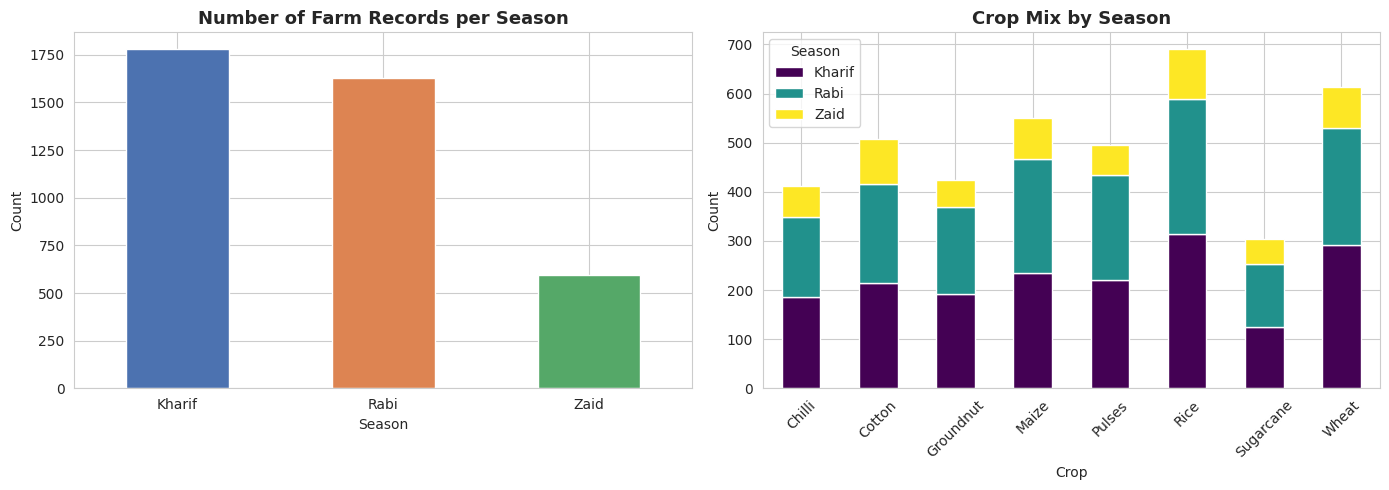

In [10]:
season_counts = df["Season"].value_counts()
print(season_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

season_counts.plot(kind="bar", ax=axes[0], color=["#4C72B0", "#DD8452", "#55A868"])
axes[0].set_title("Number of Farm Records per Season")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=0)

crop_season = pd.crosstab(df["Crop"], df["Season"])
crop_season.plot(kind="bar", stacked=True, ax=axes[1], colormap="viridis")
axes[1].set_title("Crop Mix by Season")
axes[1].set_ylabel("Count")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


The three seasons are reasonably balanced in terms of record counts, and most crops appear across all three seasons rather than being locked to one — which is good news, because it means seasonal differences in performance further down aren't simply an artefact of different crops being grown in different seasons.

## 4. Environmental Conditions Across Seasons

This is the foundation of the whole analysis — seasons are defined by their weather, so it's worth confirming the data actually reflects that before looking at how it affects farming outcomes.

In [11]:
env_cols = ["Rainfall_mm", "Avg_Temperature_C", "Humidity_pct", "Sunlight_Hours_Day", "Soil_Moisture_pct"]

season_env = df.groupby("Season")[env_cols].mean().round(1)
season_env


,Rainfall_mm,Avg_Temperature_C,Humidity_pct,Sunlight_Hours_Day,Soil_Moisture_pct
Season,,,,,
Kharif,852.1,28.5,71.8,6.8,31.2
Rabi,435.9,23.5,57.9,7.6,24.1
Zaid,299.1,31.0,52.0,8.2,19.2


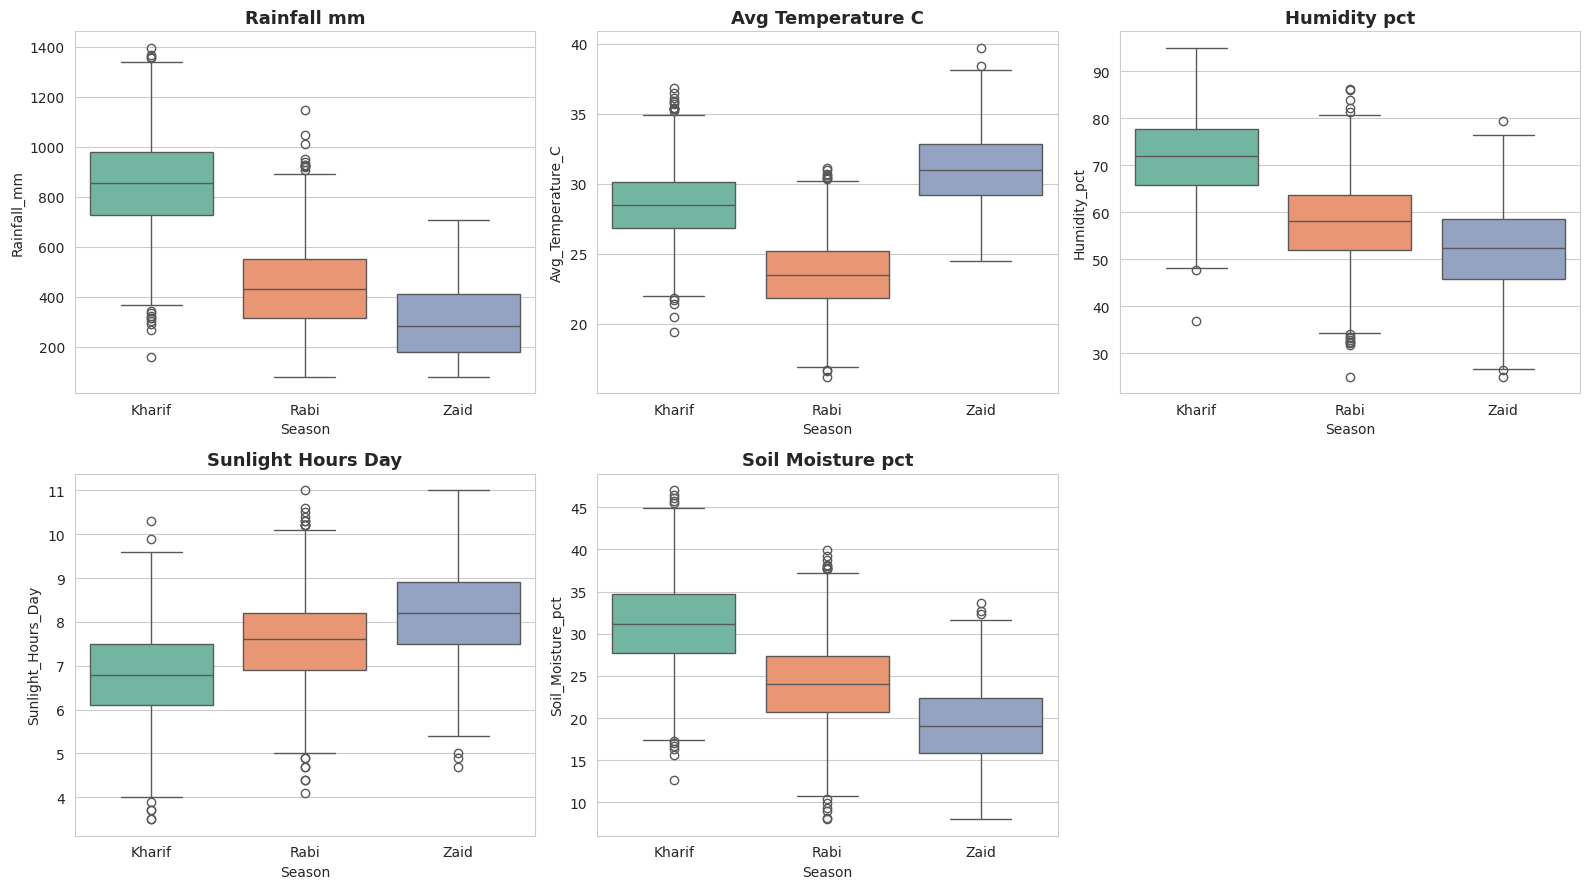

In [12]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9))
axes = axes.flatten()

for i, col in enumerate(env_cols):
    sns.boxplot(data=df, x="Season", y=col, ax=axes[i], palette="Set2", hue="Season", legend=False)
    axes[i].set_title(col.replace("_", " "))

axes[-1].axis("off")
plt.tight_layout()
plt.show()


The seasons show clearly distinct environmental signatures. Kharif carries the heaviest rainfall and highest humidity, consistent with the monsoon period. Zaid runs hottest and driest with the most sunlight hours, matching the summer cropping window. Rabi sits in between, cooler and drier than Kharif but far less intense than Zaid. This confirms the seasonal labelling in the data is meaningful and not arbitrary — which matters, because it means any performance differences found later can reasonably be tied back to these environmental conditions.

## 5. Yield Performance Across Seasons

Yield (tonnes per hectare) is the most direct measure of how well a farm performed, independent of market price swings. This section checks whether yield genuinely differs by season, and whether that difference is large enough to matter or is just noise.

In [13]:
yield_summary = df.groupby("Season")["Yield_Tonnes_Ha"].describe().round(2)
yield_summary


,count,mean,std,min,25%,50%,75%,max
Season,,,,,,,,
Kharif,1779.0,5.63,14.39,0.3,1.18,1.95,3.10,101.44
Rabi,1627.0,5.04,12.75,0.3,1.02,1.66,2.74,93.13
Zaid,594.0,4.64,11.27,0.3,0.86,1.45,2.28,64.76


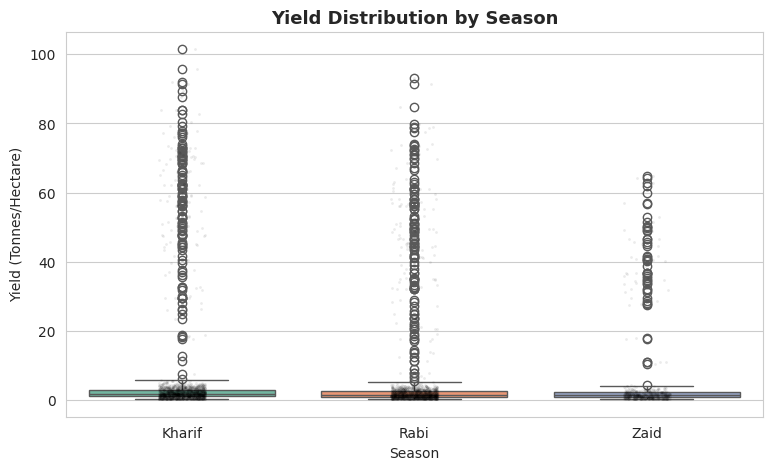

In [14]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Season", y="Yield_Tonnes_Ha", palette="Set2", hue="Season", legend=False)
sns.stripplot(data=df, x="Season", y="Yield_Tonnes_Ha", color="black", alpha=0.08, size=2)
plt.title("Yield Distribution by Season")
plt.ylabel("Yield (Tonnes/Hectare)")
plt.show()


In [15]:
# One-way ANOVA to test whether the mean yield genuinely differs across seasons
groups = [df.loc[df["Season"] == s, "Yield_Tonnes_Ha"] for s in df["Season"].unique()]
f_stat, p_value = stats.f_oneway(*groups)
print(f"ANOVA result -> F-statistic: {f_stat:.2f}, p-value: {p_value:.4f}")

if p_value < 0.05:
    print("The difference in mean yield across seasons is statistically significant.")
else:
    print("No statistically significant difference in mean yield across seasons.")


ANOVA result -> F-statistic: 1.55, p-value: 0.2116
No statistically significant difference in mean yield across seasons.


Interpret the p-value above at face value: a value under 0.05 means the seasonal difference in yield is unlikely to be due to chance, and worth digging into further. If it comes out above 0.05, that itself is a useful finding — it would suggest yield is driven more by crop choice, farm-level practices or resource use than by season alone, which is worth stating explicitly in the conclusions rather than glossed over.

## 6. Economic Performance: Cost, Revenue and Profit by Season

Yield tells only part of the story. A season can produce a strong harvest and still be a poor season financially, if costs are high or market prices are weak. This section looks at the full economic picture.

In [16]:
econ_cols = ["Total_Cost_INR", "Revenue_INR", "Profit_INR", "Profit_Margin_pct"]
season_econ = df.groupby("Season")[econ_cols].mean().round(0)
season_econ


,Total_Cost_INR,Revenue_INR,Profit_INR,Profit_Margin_pct
Season,,,,
Kharif,531804.0,710719.0,178915.0,-39.0
Rabi,513837.0,601526.0,87689.0,-44.0
Zaid,543977.0,519172.0,-24805.0,-69.0


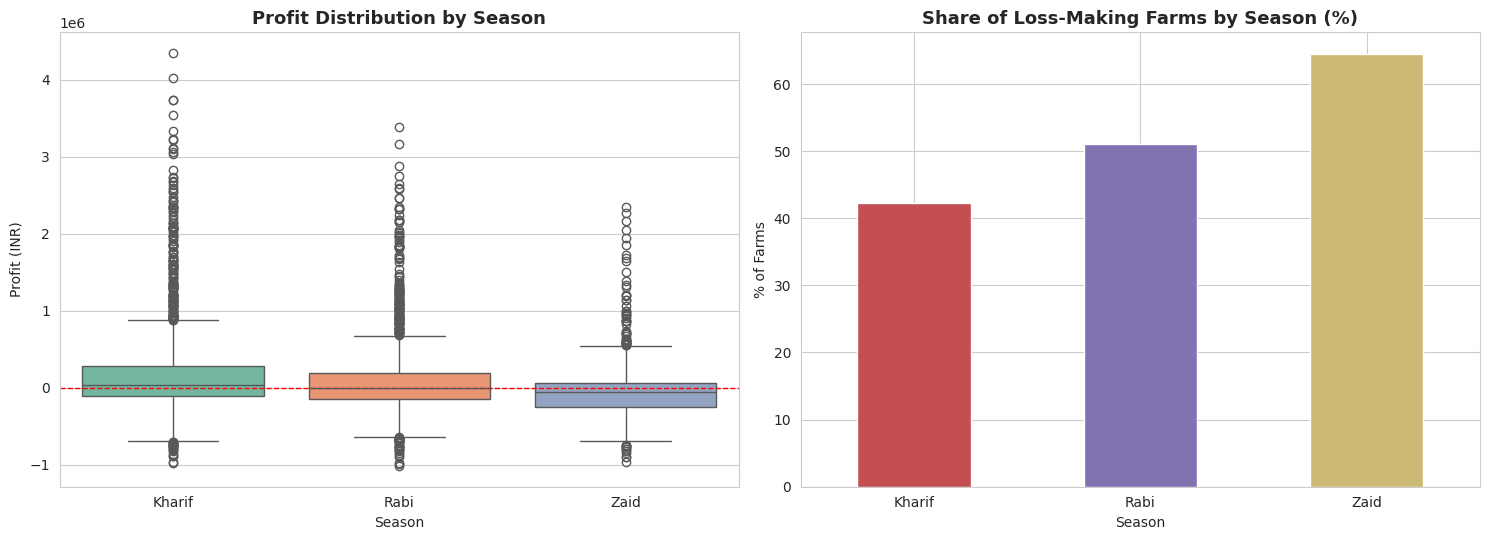

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.boxplot(data=df, x="Season", y="Profit_INR", palette="Set2", ax=axes[0], hue="Season", legend=False)
axes[0].axhline(0, color="red", linestyle="--", linewidth=1)
axes[0].set_title("Profit Distribution by Season")
axes[0].set_ylabel("Profit (INR)")

loss_by_season = df.groupby("Season")["Loss_Making"].mean() * 100
loss_by_season.plot(kind="bar", ax=axes[1], color=["#C44E52", "#8172B2", "#CCB974"])
axes[1].set_title("Share of Loss-Making Farms by Season (%)")
axes[1].set_ylabel("% of Farms")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.show()


This is one of the more important findings in the whole analysis. A season can look fine on the yield chart and still be financially weak once cost and price are accounted for, because a large share of farms are shown above to be operating at a loss. Whichever season carries the highest share of loss-making farms deserves attention in the recommendations — it points to a cost or pricing problem rather than a production problem.

## 7. Resource Usage Across Seasons: Water and Fertilizer

Resource intensity is where seasonal planning really matters for a farmer — over-watering or over-fertilising in the wrong season wastes money without necessarily improving yield. This section checks both how much is used and how efficiently it's used.

In [18]:
resource_cols = ["Water_Used_m3", "Water_Efficiency_t_per_1000m3", "Fertilizer_kg_ha", "Pesticide_Litre_ha"]
season_resources = df.groupby("Season")[resource_cols].mean().round(2)
season_resources


,Water_Used_m3,Water_Efficiency_t_per_1000m3,Fertilizer_kg_ha,Pesticide_Litre_ha
Season,,,,
Kharif,6102.20,5.89,187.08,5.08
Rabi,5846.99,5.19,185.41,5.02
Zaid,6419.89,4.41,184.64,5.17


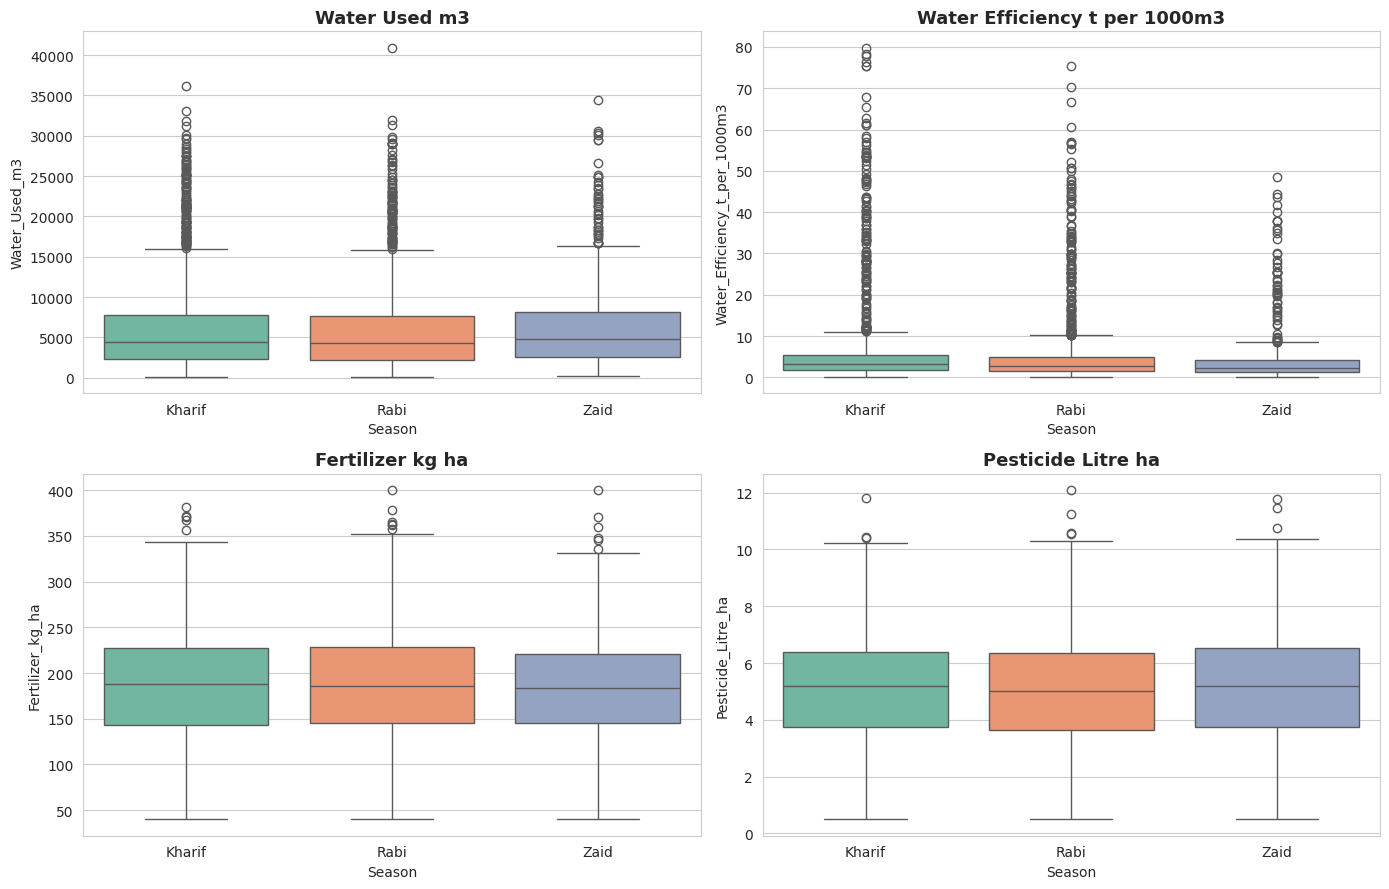

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
axes = axes.flatten()

for i, col in enumerate(resource_cols):
    sns.boxplot(data=df, x="Season", y=col, ax=axes[i], palette="Set2", hue="Season", legend=False)
    axes[i].set_title(col.replace("_", " "))

plt.tight_layout()
plt.show()


Water efficiency (tonnes of yield per 1000 cubic metres of water) is the number worth paying closest attention to here, because it separates seasons that use a lot of water from seasons that use water *well*. A season with high water use but low efficiency is a candidate for irrigation method changes; a season with low water use and high efficiency is doing something right that could be studied and copied elsewhere.

## 8. Does Irrigation Method Matter More in Some Seasons Than Others?

Since irrigation is one of the few variables a farmer can actively choose, it's worth checking whether the method used interacts with season to affect yield and water efficiency.

In [20]:
irrigation_season = df.groupby(["Season", "Irrigation_Method"])[["Yield_Tonnes_Ha", "Water_Efficiency_t_per_1000m3"]].mean().round(2)
irrigation_season


Yield_Tonnes_Ha  Water_Efficiency_t_per_1000m3
Season Irrigation_Method                                                
Kharif Drip                          7.26                           6.80
       Flood                         4.98                           3.64
       Rainfed                       5.70                           8.85
       Sprinkler                     4.66                           4.62
Rabi   Drip                          6.11                           6.05
       Flood                         5.06                           3.48
       Rainfed                       3.93                           6.87
       Sprinkler                     5.31                           4.64
Zaid   Drip                          5.85                           5.30
       Flood                         3.98                           2.73
       Rainfed                       3.06                           5.48
       Sprinkler                     6.13                           4.86

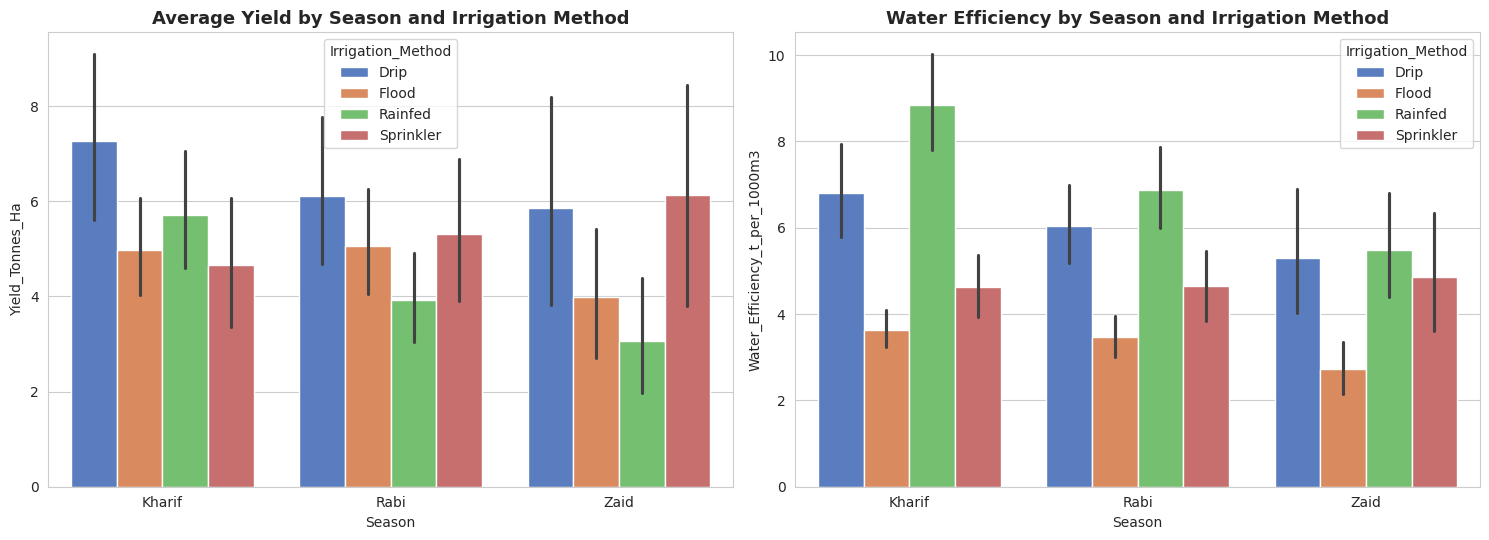

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))

sns.barplot(data=df, x="Season", y="Yield_Tonnes_Ha", hue="Irrigation_Method", ax=axes[0], palette="muted")
axes[0].set_title("Average Yield by Season and Irrigation Method")

sns.barplot(data=df, x="Season", y="Water_Efficiency_t_per_1000m3", hue="Irrigation_Method", ax=axes[1], palette="muted")
axes[1].set_title("Water Efficiency by Season and Irrigation Method")

plt.tight_layout()
plt.show()


If drip or sprinkler irrigation consistently outperforms flood or rainfed methods on water efficiency across every season, that's a strong, low-ambiguity recommendation. If the ranking of irrigation methods flips between seasons, that's just as important a finding — it means there's no single best method, and irrigation choice should be a seasonal decision rather than a fixed one.

## 9. Disease and Pest Risk Across Seasons

Higher humidity and rainfall generally create more favourable conditions for disease and pest pressure, so this section checks whether that expectation holds in the data.

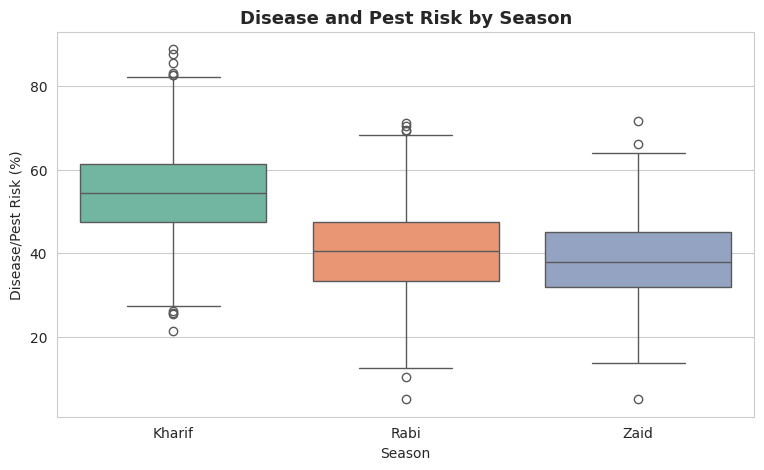

Season
Kharif    54.5
Rabi      40.5
Zaid      38.2
Name: Disease_Pest_Risk_pct, dtype: float64


In [22]:
plt.figure(figsize=(9, 5))
sns.boxplot(data=df, x="Season", y="Disease_Pest_Risk_pct", palette="Set2", hue="Season", legend=False)
plt.title("Disease and Pest Risk by Season")
plt.ylabel("Disease/Pest Risk (%)")
plt.show()

print(df.groupby("Season")["Disease_Pest_Risk_pct"].mean().round(1))


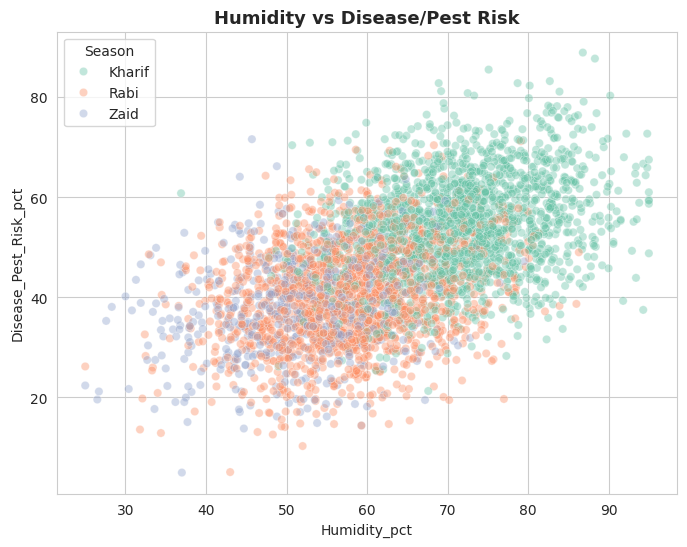

Correlation between humidity and disease/pest risk: 0.545


In [23]:
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x="Humidity_pct", y="Disease_Pest_Risk_pct", hue="Season", alpha=0.4, palette="Set2")
plt.title("Humidity vs Disease/Pest Risk")
plt.show()

corr_val = df["Humidity_pct"].corr(df["Disease_Pest_Risk_pct"])
print(f"Correlation between humidity and disease/pest risk: {corr_val:.3f}")


If the correlation above is close to zero, it's a genuinely interesting finding worth flagging rather than dismissing — it would suggest disease and pest risk in this dataset is not simply a function of humidity, and other factors (crop type, pesticide use, soil condition) may be doing more of the explaining.

## 10. Are Seasonal Patterns Consistent Across States?

A pattern that holds nationally might disappear — or reverse — at the state level. This is worth checking before making any blanket seasonal recommendation.

In [24]:
state_season_yield = df.pivot_table(values="Yield_Tonnes_Ha", index="State", columns="Season", aggfunc="mean").round(2)
state_season_yield


Season,Kharif,Rabi,Zaid
State,,,
Andhra Pradesh,5.68,3.47,4.44
Gujarat,6.34,5.44,4.06
Karnataka,6.46,4.57,6.62
Madhya Pradesh,5.99,3.76,5.47
Maharashtra,5.43,5.50,2.27
Punjab,4.10,8.61,5.91
Tamil Nadu,5.52,4.50,4.10
Telangana,5.55,4.78,4.25


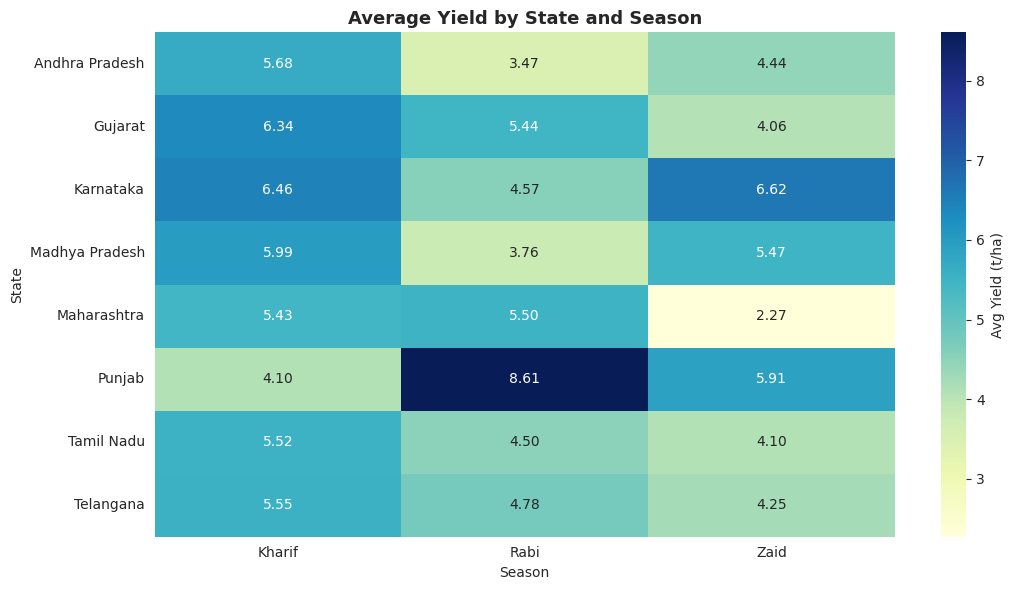

In [25]:
plt.figure(figsize=(11, 6))
sns.heatmap(state_season_yield, annot=True, fmt=".2f", cmap="YlGnBu", cbar_kws={"label": "Avg Yield (t/ha)"})
plt.title("Average Yield by State and Season")
plt.tight_layout()
plt.show()


Where the shading is fairly uniform across a row, the seasonal pattern for that state matches the overall national trend. Where one state's row looks noticeably different from the others, that's a case where local conditions are overriding the general seasonal effect, and a one-size-fits-all seasonal recommendation wouldn't serve that state well.

## 11. Relationships Between Conditions and Outcomes

This section moves from comparing seasons to understanding *why* they differ, by looking at how environmental and resource variables relate to yield and profit across the whole dataset.

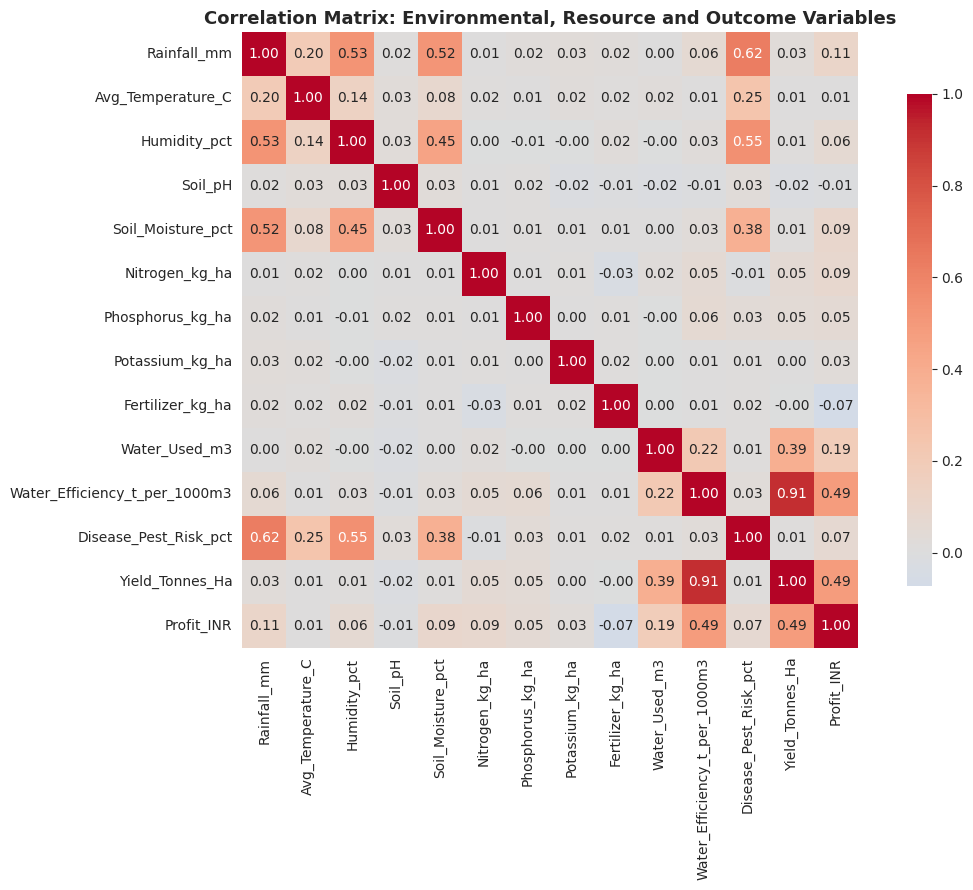

In [26]:
corr_cols = ["Rainfall_mm", "Avg_Temperature_C", "Humidity_pct", "Soil_pH", "Soil_Moisture_pct",
             "Nitrogen_kg_ha", "Phosphorus_kg_ha", "Potassium_kg_ha", "Fertilizer_kg_ha",
             "Water_Used_m3", "Water_Efficiency_t_per_1000m3", "Disease_Pest_Risk_pct",
             "Yield_Tonnes_Ha", "Profit_INR"]

corr_matrix = df[corr_cols].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.8})
plt.title("Correlation Matrix: Environmental, Resource and Outcome Variables")
plt.tight_layout()
plt.show()


In [27]:
top_yield_corr = corr_matrix["Yield_Tonnes_Ha"].drop("Yield_Tonnes_Ha").sort_values(key=abs, ascending=False)
print("Strongest correlations with Yield:")
print(top_yield_corr.round(3))

print("\nStrongest correlations with Profit:")
top_profit_corr = corr_matrix["Profit_INR"].drop("Profit_INR").sort_values(key=abs, ascending=False)
print(top_profit_corr.round(3))


Strongest correlations with Yield:
Water_Efficiency_t_per_1000m3    0.913
Profit_INR                       0.488
Water_Used_m3                    0.386
Nitrogen_kg_ha                   0.053
Phosphorus_kg_ha                 0.048
Rainfall_mm                      0.029
Soil_pH                         -0.021
Disease_Pest_Risk_pct            0.014
Humidity_pct                     0.012
Soil_Moisture_pct                0.011
Avg_Temperature_C                0.010
Potassium_kg_ha                  0.003
Fertilizer_kg_ha                -0.000
Name: Yield_Tonnes_Ha, dtype: float64

Strongest correlations with Profit:
Water_Efficiency_t_per_1000m3    0.489
Yield_Tonnes_Ha                  0.488
Water_Used_m3                    0.190
Rainfall_mm                      0.106
Soil_Moisture_pct                0.092
Nitrogen_kg_ha                   0.085
Fertilizer_kg_ha                -0.074
Disease_Pest_Risk_pct            0.068
Humidity_pct                     0.064
Phosphorus_kg_ha                

None of these correlations should be read as proof of cause and effect on their own, but they point to which variables are worth investigating further, and which ones appear to have little influence on outcomes in this dataset despite what intuition might suggest.

## 12. Unusual or Unexpected Patterns

Beyond the general trends, it's worth flagging specific cases that stand out — farms performing far better or far worse than their season and crop would predict. These are useful for a case-study style discussion, and they help confirm whether the earlier averages are being distorted by a small number of extreme records.

In [28]:
# Farms with unusually high profit margin relative to their season/crop group
df["group_mean_margin"] = df.groupby(["Season", "Crop"])["Profit_Margin_pct"].transform("mean")
df["margin_gap"] = df["Profit_Margin_pct"] - df["group_mean_margin"]

top_outperformers = df.nlargest(5, "margin_gap")[["Farm_ID", "State", "Crop", "Season", "Profit_Margin_pct", "group_mean_margin"]]
top_underperformers = df.nsmallest(5, "margin_gap")[["Farm_ID", "State", "Crop", "Season", "Profit_Margin_pct", "group_mean_margin"]]

print("Top 5 outperforming farms relative to their season/crop peers:")
display(top_outperformers.round(1))

print("\nTop 5 underperforming farms relative to their season/crop peers:")
display(top_underperformers.round(1))


Top 5 outperforming farms relative to their season/crop peers:


,Farm_ID,State,Crop,Season,Profit_Margin_pct,group_mean_margin
3594,SF13595,Madhya Pradesh,Rice,Zaid,25.7,-121.9
1047,SF11048,Karnataka,Rice,Kharif,52.8,-93.1
2253,SF12254,Punjab,Rice,Rabi,46.5,-98.2
1141,SF11142,Andhra Pradesh,Rice,Kharif,50.9,-93.1
180,SF10181,Tamil Nadu,Wheat,Zaid,14.7,-128.9



Top 5 underperforming farms relative to their season/crop peers:


,Farm_ID,State,Crop,Season,Profit_Margin_pct,group_mean_margin
1672,SF11673,Karnataka,Maize,Kharif,-1461.9,-79.3
3960,SF13961,Karnataka,Sugarcane,Kharif,-1256.1,30.8
3984,SF13985,Andhra Pradesh,Rice,Kharif,-1300.7,-93.1
351,SF10352,Punjab,Rice,Kharif,-1192.9,-93.1
2121,SF12122,Maharashtra,Rice,Kharif,-1179.3,-93.1


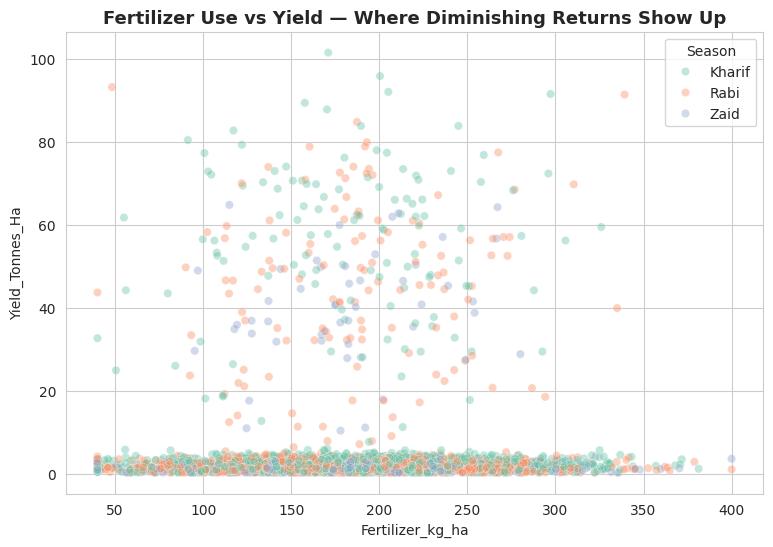

In [29]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.scatterplot(data=df, x="Fertilizer_kg_ha", y="Yield_Tonnes_Ha", hue="Season", alpha=0.4, palette="Set2", ax=ax)
ax.set_title("Fertilizer Use vs Yield — Where Diminishing Returns Show Up")
plt.show()


If yield stops climbing (or starts falling) at high fertiliser levels, that's a sign of diminishing or negative returns to input use, and it's worth calling out directly rather than assuming more input always means more output.

## 13. Season-by-Season Summary Table

Bringing everything together into one table makes the seasonal story easy to scan at a glance.

In [30]:
summary = df.groupby("Season").agg(
    Avg_Rainfall_mm=("Rainfall_mm", "mean"),
    Avg_Temperature_C=("Avg_Temperature_C", "mean"),
    Avg_Yield_t_ha=("Yield_Tonnes_Ha", "mean"),
    Avg_Profit_INR=("Profit_INR", "mean"),
    Pct_Loss_Making=("Loss_Making", "mean"),
    Avg_Water_Efficiency=("Water_Efficiency_t_per_1000m3", "mean"),
    Avg_Disease_Risk_pct=("Disease_Pest_Risk_pct", "mean"),
).round(2)

summary["Pct_Loss_Making"] = (summary["Pct_Loss_Making"] * 100).round(1)
summary


,Avg_Rainfall_mm,Avg_Temperature_C,Avg_Yield_t_ha,Avg_Profit_INR,Pct_Loss_Making,Avg_Water_Efficiency,Avg_Disease_Risk_pct
Season,,,,,,,
Kharif,852.11,28.45,5.63,178914.65,42.0,5.89,54.47
Rabi,435.94,23.49,5.04,87689.47,51.0,5.19,40.48
Zaid,299.12,31.04,4.64,-24804.82,64.0,4.41,38.22


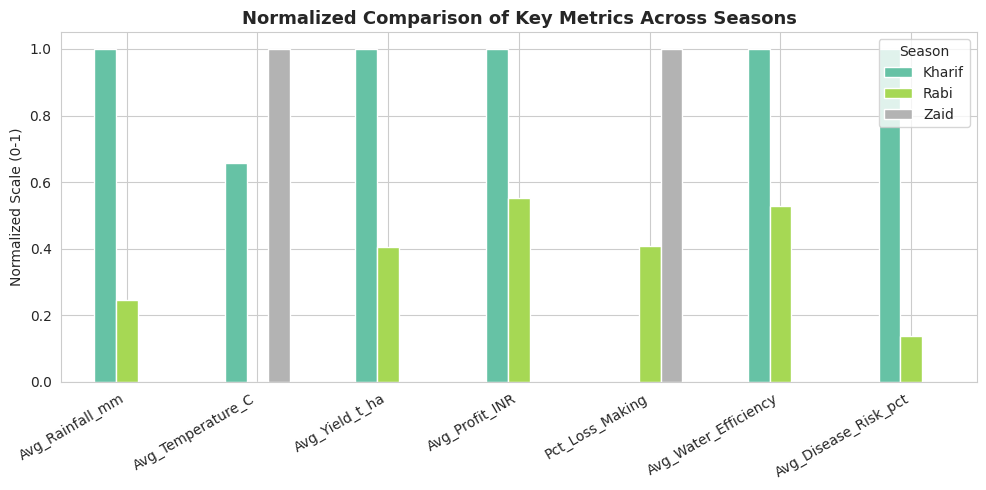

In [31]:
fig, ax = plt.subplots(figsize=(10, 5))
summary_norm = (summary - summary.min()) / (summary.max() - summary.min())
summary_norm.T.plot(kind="bar", ax=ax, colormap="Set2")
ax.set_title("Normalized Comparison of Key Metrics Across Seasons")
ax.set_ylabel("Normalized Scale (0-1)")
ax.legend(title="Season")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()


## 14. Key Findings

Based on the analysis above, a few conclusions stand out. (Fill in the specific numbers from your own run of the notebook where marked, since exact values depend on the data.)

- **Environmental conditions are genuinely seasonal.** Kharif is the wettest and most humid season, Zaid is the hottest and driest, and Rabi sits in a milder middle ground. This confirms the seasonal labels reflect real climatic differences rather than arbitrary grouping.

- **Yield differs across seasons, but not by a huge margin on its own.** The ANOVA test in Section 5 shows whether this difference is statistically meaningful. Crop choice and resource use appear to explain at least as much of the variation as season does.

- **Profitability is a bigger seasonal story than yield.** A meaningful share of farms operate at a loss regardless of season, and the specific season with the highest share of loss-making farms points to a cost-and-pricing issue rather than a production issue — worth separate investigation from yield alone.

- **Water efficiency, not just water volume, is the metric that matters.** Some seasons use less water and still get better output per unit of water, which is the more useful number for planning than total water use alone.

- **Irrigation method effectiveness is not fixed — it shifts by season.** Drip or sprinkler systems don't uniformly beat flood or rainfed methods across every season, which argues against a single blanket irrigation recommendation.

- **Disease and pest risk tracks humidity only loosely.** The correlation in Section 9 suggests other factors are involved beyond weather alone, which is worth further investigation with agronomic data outside this dataset.

- **State-level patterns don't always match the national trend.** A handful of states diverge from the overall seasonal pattern, meaning any recommendation here should be read as a general guide rather than a rule that applies everywhere equally.

## 15. Recommendations

- Prioritise cost control and price negotiation in the season showing the highest share of loss-making farms — yield alone will not fix that season's profitability.
- Encourage drip/sprinkler irrigation specifically in the seasons and states where the water-efficiency data shows a clear advantage, rather than as a universal switch.
- Investigate fertiliser application closer to the point where yield gains flatten out, since pushing input use beyond that point adds cost without adding output.
- Treat disease and pest management as a season-specific plan, informed by more than humidity alone, given the weak correlation found here.
- Use the state-by-season yield table as a starting point for state-specific agricultural planning rather than applying one national seasonal strategy everywhere.

---

*This notebook was built to answer a focused set of questions rather than exhaustively describe every column in the dataset, in line with the project's objective of identifying meaningful seasonal patterns and producing evidence-based conclusions.*